# Advanced Regression

Week 1 fitted straight lines by ordinary least squares and checked when they can be trusted. This notebook goes beyond that:

1. Conditional Expectation and Flexible Regression
2. Validation and Overfitting
3. Regularization
4. Regression When Assumptions Fail
5. Regression for Probabilities

The notebook contains three kinds of cells:

- **Provided code**: complete code. Run it as it is.
- **Task**: a description of what to compute or plot, followed by an empty code cell. Write the code yourself; add more cells if needed. Each Task gives reference values so you can check your implementation.
- **Question**: a written question. Answer it in prose in the **Answer** cell (a markdown cell) below it, using the numbers from your own results.

Save this notebook and `week2_data.csv` in the same folder before running it; the Setup cell reads `week2_data.csv` from that folder.

Run the cells from top to bottom. Later sections use variables created earlier.

Be prepared to explain everything you write, both code and answers, in the session.

## Setup

This notebook requires `scikit-learn`. If it is not installed, run `pip install scikit-learn` first.

`week2_data.csv` contains the daily returns (`RET` from Week 1) of AAPL, AMZN, GOOGL, MSFT, NVDA and TSLA, and the S&P 500 daily return `MKT`, from 2019 to 2024.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, brier_score_loss

data = pd.read_csv('week2_data.csv', parse_dates=['date'], index_col='date')
data.head()

,AAPL,AMZN,GOOGL,MSFT,NVDA,TSLA,MKT
date,,,,,,,
2019-01-02,0.001141,0.024741,0.009302,-0.004430,0.020375,-0.068149,0.001269
2019-01-03,-0.099607,-0.025242,-0.027696,-0.036788,-0.060417,-0.031472,-0.024757
2019-01-04,0.042689,0.050064,0.051294,0.046509,0.064068,0.057697,0.034336
2019-01-07,-0.002226,0.034353,-0.001994,0.001275,0.052941,0.054361,0.007010
2019-01-08,0.019063,0.016612,0.008783,0.007251,-0.024895,0.001164,0.009695


# 1. Conditional Expectation and Flexible Regression

Let $X$ and $Y$ be two random variables. The conditional expectation $\mathbb{E}[Y \mid X]$ is the function $f^\ast$ of $X$ that best approximates $Y$ in the least-squares sense:

$$\mathbb{E}\left[(Y - f^\ast(X))^2\right] \le \mathbb{E}\left[(Y - f(X))^2\right] \quad \text{for any function } f \text{ of } X.$$

Least-squares regression is an attempt to estimate $\mathbb{E}[Y \mid X]$ from data. Week 1 assumed it is a straight line. Here we let the data choose the shape, and see what that flexibility costs.

We use simulated data so that the true answer is known:

$$g(x) = x\,\frac{1 + x}{1 + x^2}, \qquad X \sim \mathrm{Uniform}(-3, 3), \qquad Y = g(X) + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 0.25^2).$$

Since $\mathbb{E}[Y \mid X] = g(X)$, no model can achieve an expected test MSE below the noise variance, $0.25^2 = 0.0625$. There are only 40 training points; the 1,000 test points are used to measure how well a fit generalizes.

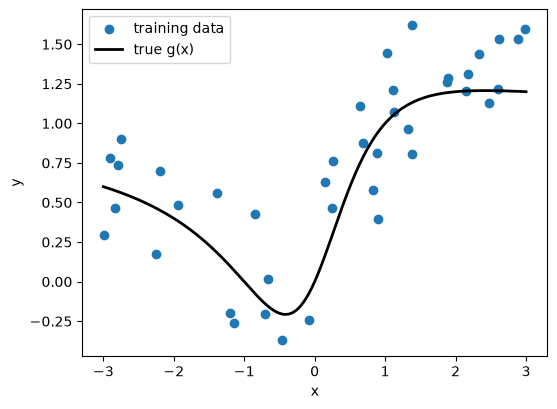

In [2]:
def g(x):
    return x * (1 + x) / (1 + x ** 2)

rng = np.random.default_rng(0)
x_train = rng.uniform(-3, 3, 40)
y_train = g(x_train) + 0.25 * rng.standard_normal(40)
x_test = rng.uniform(-3, 3, 1000)
y_test = g(x_test) + 0.25 * rng.standard_normal(1000)
x_grid = np.linspace(-3, 3, 301)


def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(x_train, y_train, label='training data')
ax.plot(x_grid, g(x_grid), 'k', lw=2, label='true g(x)')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend()
plt.show()

Polynomials are fitted with `np.polynomial.Polynomial.fit`. The functions below implement the other three fitting methods used in this section.

- **Piecewise linear**: a continuous function made of straight segments that may bend at `n_knots` equally spaced points. It is a linear regression on the basis $1, x, \max(x - k_1, 0), \dots, \max(x - k_m, 0)$.
- **Nadaraya-Watson (NW) kernel regression**: at each point, a weighted average of the nearby $y$ values, with Gaussian weights whose width is the `bandwidth`.
- **Local linear regression**: at each point, a weighted straight-line fit with the same weights, evaluated at that point.

In [3]:
def piecewise_linear_fit(x, y, n_knots):
    """Least-squares fit of a continuous piecewise linear function with n_knots equally spaced
    interior knots on [-3, 3]. Returns a function that evaluates the fit."""
    knots = np.linspace(-3, 3, n_knots + 2)[1:-1]

    def basis(z):
        return np.column_stack([np.ones_like(z), z] + [np.maximum(z - k, 0) for k in knots])

    coef = np.linalg.lstsq(basis(x), y, rcond=None)[0]
    return lambda z: basis(z) @ coef


def gauss_kernel(u):
    return np.exp(-u ** 2 / 2)


def nw_regression(x_eval, x_data, y_data, bandwidth):
    """Nadaraya-Watson estimate of E[Y | X = x] at each point of x_eval."""
    w = gauss_kernel((x_data[:, None] - x_eval) / bandwidth)
    return (w * y_data[:, None]).sum(axis=0) / w.sum(axis=0)


def local_linear_regression(x_eval, x_data, y_data, bandwidth):
    """Local linear estimate of E[Y | X = x] at each point of x_eval."""
    d = x_data[:, None] - x_eval
    w = gauss_kernel(d / bandwidth)
    s0, s1, s2 = w.sum(axis=0), (w * d).sum(axis=0), (w * d ** 2).sum(axis=0)
    t0, t1 = (w * y_data[:, None]).sum(axis=0), (w * d * y_data[:, None]).sum(axis=0)
    return (s2 * t0 - s1 * t1) / (s0 * s2 - s1 ** 2)

**Task 1A.** For degrees 1, 3, 5, 9 and 15, fit a polynomial to (`x_train`, `y_train`) with `np.polynomial.Polynomial.fit`. Report the train MSE and the test MSE of each degree in one table, and plot the fits for degrees 1, 3 and 15 on `x_grid` together with `g`.

Reference: the test MSE is 0.1124 for degree 3, 0.0760 for degree 9 and 0.0905 for degree 15.

        train MSE  test MSE
degree                     
1          0.1797    0.2180
3          0.0910    0.1124
5          0.0681    0.0862
9          0.0633    0.0760
15         0.0565    0.0905


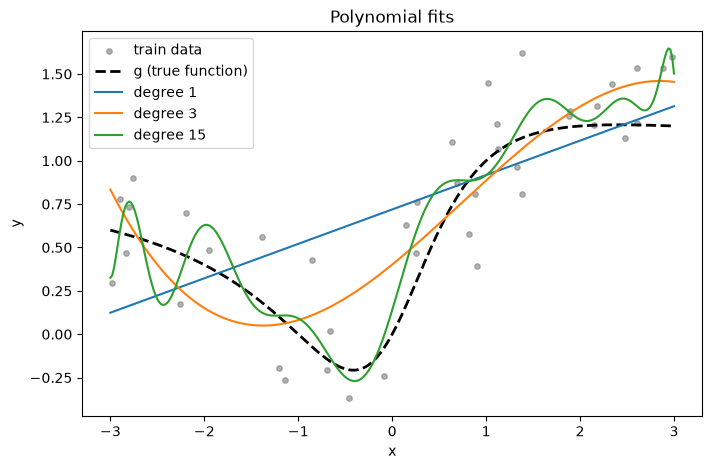

In [4]:
degrees = [1, 3, 5, 9, 15]
fits = {d: np.polynomial.Polynomial.fit(x_train, y_train, deg=d) for d in degrees}
table = pd.DataFrame({
    "degree": degrees,
    "train MSE": [mse(y_train, fits[d](x_train)) for d in degrees],
    "test MSE": [mse(y_test, fits[d](x_test)) for d in degrees],
}).set_index("degree")
print(table.to_string(float_format="{:.4f}".format))

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, s=15, color="gray", alpha=0.6, label="train data")
plt.plot(x_grid, g(x_grid), "k--", lw=2, label="g (true function)")
for d in [1,3,15]:
    plt.plot(x_grid, fits[d](x_grid), label=f"degree {d}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Polynomial fits")
plt.show()

**Task 1B.** Repeat Task 1A with `piecewise_linear_fit` for `n_knots` = 1, 3, 6, 12 and 25, and plot the fits for 1, 6 and 25 knots.

Reference: the test MSE is 0.0789 with 6 knots and 0.5644 with 25 knots.

         train MSE  test MSE
n_knots                     
1           0.1119    0.1313
3           0.0811    0.0925
6           0.0635    0.0789
12          0.0481    0.1325
25          0.0257    0.5644


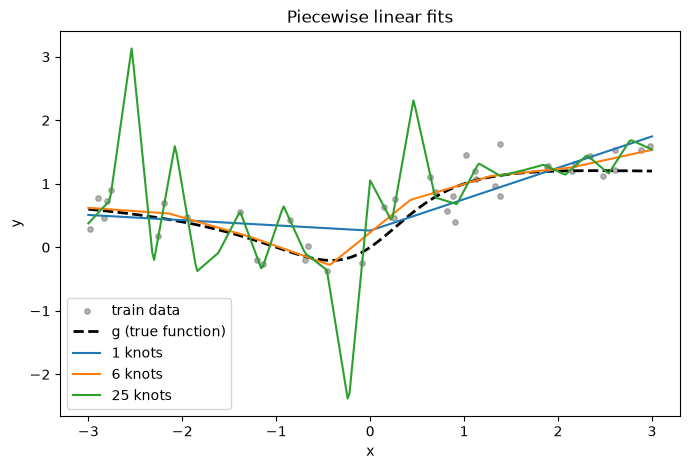

In [5]:
n_knots = [1, 3, 6, 12, 25]
fits = {k: piecewise_linear_fit(x_train, y_train, n_knots=k) for k in n_knots}
table = pd.DataFrame({
    "n_knots": n_knots,
    "train MSE": [mse(y_train, fits[k](x_train)) for k in n_knots],
    "test MSE": [mse(y_test, fits[k](x_test)) for k in n_knots],
}).set_index("n_knots")
print(table.to_string(float_format="{:.4f}".format))

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, s=15, color="gray", alpha=0.6, label="train data")
plt.plot(x_grid, g(x_grid), "k--", lw=2, label="g (true function)")
for k in [1, 6, 25]:
    plt.plot(x_grid, fits[k](x_grid), label=f"{k} knots")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Piecewise linear fits")
plt.show()


**Task 1C.** For bandwidths 0.05, 0.1, 0.3, 1 and 2, report the train and test MSE of `nw_regression` and of `local_linear_regression` in one table, and plot the NW fits for bandwidths 0.05, 0.3 and 2.

Reference: with bandwidth 0.3, the test MSE is 0.0826 for NW and 0.0800 for local linear; with bandwidth 0.05, it is 0.1223 and 0.3093.

                 NW          Local linear         
          train MSE test MSE    train MSE test MSE
bandwidth                                         
0.05         0.0183   0.1223       0.0146   0.3093
0.10         0.0303   0.0987       0.0250   0.1237
0.30         0.0640   0.0826       0.0599   0.0800
1.00         0.1050   0.1322       0.0913   0.1198
2.00         0.1877   0.2228       0.1303   0.1784


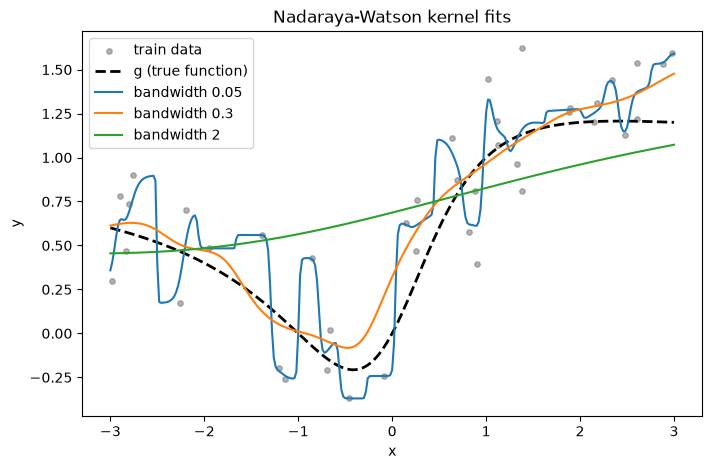

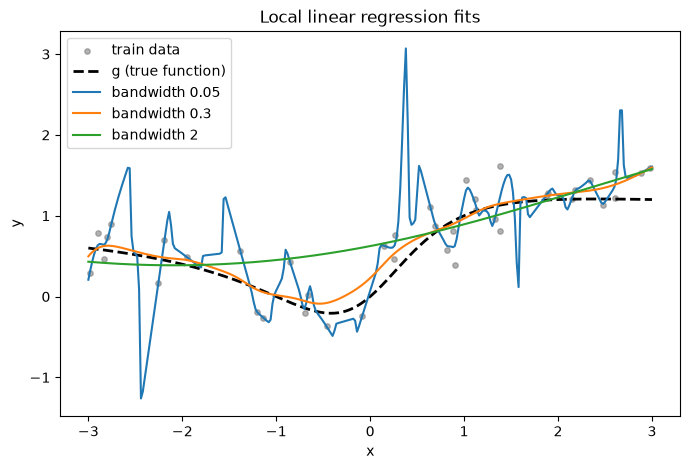

In [6]:
bandwidths = [0.05, 0.1, 0.3, 1, 2]
nw_fits = {h: nw_regression(x_grid, x_train, y_train, h) for h in bandwidths}
local_linear_fits = {h: local_linear_regression(x_grid, x_train, y_train, h) for h in bandwidths}

table = pd.DataFrame({
    ("NW", "train MSE"): [mse(y_train, nw_regression(x_train, x_train, y_train, h)) for h in bandwidths],
    ("NW", "test MSE"): [mse(y_test, nw_regression(x_test, x_train, y_train, h)) for h in bandwidths],
    ("Local linear", "train MSE"): [mse(y_train, local_linear_regression(x_train, x_train, y_train, h)) for h in bandwidths],
    ("Local linear", "test MSE"): [mse(y_test, local_linear_regression(x_test, x_train, y_train, h)) for h in bandwidths],
}, index=pd.Index(bandwidths, name="bandwidth"))
print(table.to_string(float_format="{:.4f}".format))

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, s=15, color="gray", alpha=0.6, label="train data")
plt.plot(x_grid, g(x_grid), "k--", lw=2, label="g (true function)")
for h in [0.05, 0.3, 2]:
    plt.plot(x_grid, nw_fits[h], label=f"bandwidth {h}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Nadaraya-Watson kernel fits")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, s=15, color="gray", alpha=0.6, label="train data")
plt.plot(x_grid, g(x_grid), "k--", lw=2, label="g (true function)")
for h in [0.05, 0.3, 2]:
    plt.plot(x_grid, local_linear_fits[h], label=f"bandwidth {h}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Local linear regression fits")
plt.show()


**Question 1.1**

For each of the three methods, which setting controls its flexibility? Using your train and test MSE, identify which settings underfit and which overfit, and explain why the train MSE alone would lead you to the wrong choice.

**Answer:**

Polynomial regression: degree

Piecewise linear: n_knots

Nadaraya-Watson (NW) kernel regression: bandwidth

Local linear regression: bandwidth

When both train and test MSE is high, it suggests underfit.
When train MSE is low but test MSE is high, it suggests overfit. Pursueing low train MSE can lead to overfitting.



**Question 1.2**

(a) In Task 1C, local linear regression beats NW at large bandwidths but is much worse at the smallest one. Explain both results: what does each method assume about $g$ within the window, and what does fitting a line instead of an average cost?

(b) When would you prefer a parametric basis (polynomial or piecewise linear) to a kernel method, and vice versa?

**Answer:**
(a) NW uses the best single point approaximation for every evaluating point(by weighted average of y). So it assumes g(x) to be roughly a flat line. The local linear regression assumes g(x) to be a straight line. Hence, with large bandwidth, local linear regression approximate better since titlted line gives better flexibility. Meanwhile, with small bandwidth, it is more sensitive to noise due to larger flexibility.

(b)Parametric basis is preferred if I have certain idea about the shape of g (eg. low degree polynomial or kinked curve). It is also preferred if there is relatively scarce data points because kernel method will gives bad approximation when there is only few data points within the bandwidth. Meanwhile, kernel method is preferred if g has distinct features is different places.

# 2. Validation and Overfitting

Section 1 could measure overfitting with a large, independent test set. With real data there is only one history, so the data must be split into parts used for fitting and parts used for evaluation. How the split is made matters a great deal for financial time series.

The example asks whether the market's return over the **next 20 trading days** can be predicted from its returns over the past 5, 20 and 60 days. All returns are log returns in percent.

The model is a **k-nearest-neighbour (KNN) regression**: to predict a day, it averages the targets of the `k` training days whose features are most similar. It is the same local-averaging idea as the NW regression in Section 1, with `k` playing the role of the bandwidth. Because KNN measures similarity by distance, the features must be on the same scale: `make_pipeline(StandardScaler(), KNeighborsRegressor(k))` standardizes them first, and inside cross-validation it does so using each training part only.

Performance is measured by the out-of-sample $R^2$ relative to the training mean:

$$R^2_{\text{oos}} = 1 - \frac{\sum (y - \hat y)^2}{\sum (y - \bar y_{\text{train}})^2}.$$

It is positive only if the model beats the simple forecast "the future will be like the historical average".

In [7]:
log_mkt = np.log1p(data['MKT'])
features = pd.DataFrame({f'past_{w}': log_mkt.rolling(w).sum() for w in [5, 20, 60]})
target = log_mkt[::-1].rolling(20).sum()[::-1].shift(-1).rename('fwd_20')   # sum over t+1, ..., t+20
s2 = features.join(target).dropna() * 100

X2 = s2[['past_5', 'past_20', 'past_60']].values
y2 = s2['fwd_20'].values


def oos_r2(y_test, y_pred, y_train_mean):
    return 1 - ((y_test - y_pred) ** 2).sum() / ((y_test - y_train_mean) ** 2).sum()


s2.head()

,past_5,past_20,past_60,fwd_20
date,,,,
2019-03-28,-1.391061,1.105436,11.609180,4.324808
2019-03-29,1.195816,1.089445,12.153503,3.760708
2019-04-01,2.430010,2.628559,15.810623,2.705504
2019-04-02,1.715977,2.743423,12.436356,1.950776
2019-04-03,2.396029,3.612530,11.952371,1.523580


**Task 2A.** For `make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20))`:

1. Fit it on all of `X2`, `y2` and compute the in-sample $R^2$.
2. Run 5-fold cross-validation with `KFold(5, shuffle=True, random_state=0)`: in each fold, fit on the training part, compute `oos_r2` on the test part (using the training part's mean), and average the five values.

Reference: in-sample $R^2$ = 0.2242; shuffled cross-validated $R^2_{\text{oos}}$ = 0.1245.

In [8]:
knn20 = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20))
knn20.fit(X2, y2)
y2_fitted = knn20.predict(X2)
in_sample_r2 = 1 - ((y2 - y2_fitted) ** 2).sum() / ((y2 - y2.mean()) ** 2).sum()

cv = KFold(n_splits=5, shuffle=True, random_state=0)
fold_r2 = []
for train_idx, test_idx in cv.split(X2):
    model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20))
    model.fit(X2[train_idx], y2[train_idx])
    pred = model.predict(X2[test_idx])
    fold_r2.append(oos_r2(y2[test_idx], pred, y2[train_idx].mean()))

print(f"In-sample R²: {in_sample_r2:.4f}")
print(f"Shuffled 5-fold CV R²_oos: {np.mean(fold_r2):.4f}")
print("Fold R²_oos:", [round(v, 4) for v in fold_r2])


In-sample R²: 0.2242
Shuffled 5-fold CV R²_oos: 0.1245
Fold R²_oos: [np.float64(0.1689), np.float64(0.1455), np.float64(0.0747), np.float64(0.1184), np.float64(0.1149)]


In [ ]:
kfold = KFold(5, shuffle=True, random_state=0)
scores = []
for train_index, test_index in kfold.split(X2):
    X_train_fold = X2[train_index]
    y_train_fold = y2[train_index]
    X_test_fold = X2[test_index]
    y_test_fold = y2[test_index]
    fold_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20))
    fold_model.fit(X_train_fold, y_train_fold)
    fold_predictions = fold_model.predict(X_test_fold)
    score = oos_r2(y_test_fold, fold_predictions, y_train_fold.mean())
    scores.append(score)
cv_r2_shuffled = np.mean(scores)
print(cv_r2_shuffled)

**Task 2B.** Repeat part 2 of Task 2A with two other splits:

1. `KFold(5)`: five contiguous blocks, not shuffled
2. `TimeSeriesSplit(5)`: each fold trains only on data before its test block

Reference: -0.1565 for the contiguous blocks and -0.2798 for the forward split.

In [9]:
def cv_oos_r2(splitter):
    scores = []
    for train_idx, test_idx in splitter.split(X2):
        model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20))
        model.fit(X2[train_idx], y2[train_idx])
        pred = model.predict(X2[test_idx])
        scores.append(oos_r2(y2[test_idx], pred, y2[train_idx].mean()))
    return scores

contiguous_scores = cv_oos_r2(KFold(n_splits=5))
forward_scores = cv_oos_r2(TimeSeriesSplit(n_splits=5))
print(f"Contiguous KFold R²_oos: {np.mean(contiguous_scores):.4f}")
print("Fold R²_oos:", [round(v, 4) for v in contiguous_scores])
print(f"Forward TimeSeriesSplit R²_oos: {np.mean(forward_scores):.4f}")
print("Fold R²_oos:", [round(v, 4) for v in forward_scores])


Contiguous KFold R²_oos: -0.1565
Fold R²_oos: [np.float64(0.0271), np.float64(-0.5458), np.float64(0.0951), np.float64(-0.0729), np.float64(-0.2862)]
Forward TimeSeriesSplit R²_oos: -0.2798
Fold R²_oos: [np.float64(-0.2397), np.float64(-0.6188), np.float64(-0.094), np.float64(-0.0968), np.float64(-0.3498)]


**Task 2C.** For `LinearRegression()` and for the standardized KNN with `k` = 1, 5, 20 and 100, report the in-sample $R^2$ and the cross-validated $R^2_{\text{oos}}$ under all three splits in one table. Which model would each split select, and does any model beat the historical mean?

Reference: OLS has $R^2_{\text{oos}}$ = -0.1275 under the forward split; KNN with `k` = 100 has 0.0451, -0.0685 and -0.0526 under the shuffled, contiguous and forward splits.

In [10]:
models = {"LinearRegression": LinearRegression()}
models.update({f"KNN k={k}": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)) for k in [1, 5, 20, 100]})

splits = {
    "shuffled": KFold(n_splits=5, shuffle=True, random_state=0),
    "contiguous": KFold(n_splits=5),
    "forward": TimeSeriesSplit(n_splits=5),
}
rows = []
for name, estimator in models.items():
    estimator.fit(X2, y2)
    fitted = estimator.predict(X2)
    row = {"model": name, "in-sample R²": 1 - ((y2 - fitted) ** 2).sum() / ((y2 - y2.mean()) ** 2).sum()}
    for split_name, splitter in splits.items():
        scores = []
        for train_idx, test_idx in splitter.split(X2):
            if name == "LinearRegression":
                model = LinearRegression()
            else:
                k = int(name.split("=")[1])
                model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
            model.fit(X2[train_idx], y2[train_idx])
            pred = model.predict(X2[test_idx])
            scores.append(oos_r2(y2[test_idx], pred, y2[train_idx].mean()))
        row[f"{split_name} R²_oos"] = np.mean(scores)
    rows.append(row)

results_2c = pd.DataFrame(rows).set_index("model")
print(results_2c.to_string(float_format="{:.4f}".format))

for split_name in splits:
    col = f"{split_name} R²_oos"
    best = results_2c[col].idxmax()
    best_score = results_2c[col].max()
    print(f"{split_name}: selects {best} (R²_oos={best_score:.4f}); beats historical mean: {best_score > 0}")


                  in-sample R²  shuffled R²_oos  contiguous R²_oos  forward R²_oos
model                                                                             
LinearRegression        0.0469           0.0325            -0.1618         -0.1275
KNN k=1                 1.0000          -0.5784            -1.5631         -2.8165
KNN k=5                 0.4195           0.0635            -0.3887         -0.9346
KNN k=20                0.2242           0.1245            -0.1565         -0.2798
KNN k=100               0.0762           0.0451            -0.0685         -0.0526
shuffled: selects KNN k=20 (R²_oos=0.1245); beats historical mean: True
contiguous: selects KNN k=100 (R²_oos=-0.0685); beats historical mean: False
forward: selects KNN k=100 (R²_oos=-0.0526); beats historical mean: False


**Question 2.1**

The shuffled split suggests that next month's market return can be predicted, while the other two splits say it cannot. Explain what causes the difference. Why does the contiguous split, which also trains on data from after the test block, agree with the forward split?

**Answer:**
The shuffled split introduce the future data leakage into training and hence such performance is achieved mainly because future data near the tested date is used to make prediction. For continguous split, although it also uses future data, it can only include the future data that is next to the current testing block. These data is not that relevant and useful, hence it seems to agree with the forward split.

**Question 2.2**

Using Task 2C, which model would you have chosen from the in-sample $R^2$, from the shuffled split and from the forward split, and what would you have expected from it in real use? Would you use any model at all? State a rule for validating any model on financial time series.

**Answer:**

in-sample: KNN k=1 (of course!)

shuffled split: KNN k=20

foward split: KNN k=100

I would expect them to underperform than the historical mean value method since the forward split R^2_OOS are all less than 0. 

Lesson to learn is always check whether future data is used for prediction when validating.

# 3. Regularization

With many predictors, OLS fits the noise as well as the signal. Regularization adds a penalty on the size of the coefficients to the least-squares objective:

$$\text{Ridge:}\ \min_\beta \sum_t (y_t - x_t^\top\beta)^2 + \alpha \sum_j \beta_j^2 \qquad\qquad \text{Lasso:}\ \min_\beta \tfrac{1}{2n}\sum_t (y_t - x_t^\top\beta)^2 + \alpha \sum_j |\beta_j|$$

A larger $\alpha$ means a stronger pull towards zero. Because the penalty depends on the size of each coefficient, predictors are put on the same scale (standardized) first.

We start with simulated data where the truth is known: 50 correlated predictors, of which only the first 5 matter, and only 80 training observations.

In [11]:
p = 50
corr = 0.6 ** np.abs(np.subtract.outer(np.arange(p), np.arange(p)))
chol = np.linalg.cholesky(corr)
beta_true = np.zeros(p)
beta_true[:5] = [3, -2, 1.5, 1, -1]

rng3 = np.random.default_rng(0)
X3_train = rng3.standard_normal((80, p)) @ chol.T
y3_train = X3_train @ beta_true + 2 * rng3.standard_normal(80)
X3_test = rng3.standard_normal((2000, p)) @ chol.T
y3_test = X3_test @ beta_true + 2 * rng3.standard_normal(2000)
# every predictor already has mean 0 and variance 1, so no standardization is needed here


def plot_paths(alphas, coefs, title, ax):
    """Plot coefficient paths. coefs has shape (len(alphas), p).
    The 5 true predictors are drawn in colour, the other 45 in grey."""
    coefs = np.asarray(coefs)
    for j in range(coefs.shape[1]):
        if j < 5:
            ax.plot(alphas, coefs[:, j], lw=2, label=f'x{j + 1} (true {beta_true[j]:g})')
        else:
            ax.plot(alphas, coefs[:, j], color='0.75', lw=0.8)
    ax.set_xscale('log')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel('alpha')
    ax.set_ylabel('coefficient')
    ax.set_title(title)
    ax.legend(fontsize=8)


ridge_alphas = np.logspace(-2, 3, 50)
lasso_alphas = np.logspace(-3, 0.5, 50)

**Task 3A.** Fit `LinearRegression()`, `Ridge(alpha=10)` and `Lasso(alpha=0.1)` on the simulated training data. For each, report the train MSE, the test MSE, the number of non-zero coefficients, and how many of the 5 true predictors have a non-zero coefficient.

Reference: the test MSE is 11.756 for OLS, 7.220 for Ridge and 5.301 for Lasso, which keeps 22 non-zero coefficients.

In [12]:
models_3a = {
    "OLS": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10),
    "Lasso (alpha=0.1)": Lasso(alpha=0.1),
}
rows_3a = []
for name, model in models_3a.items():
    model.fit(X3_train, y3_train)
    train_pred = model.predict(X3_train)
    test_pred = model.predict(X3_test)
    coef = model.coef_
    nonzero = np.abs(coef) > 1e-8
    rows_3a.append({
        "model": name,
        "train MSE": mse(y3_train, train_pred),
        "test MSE": mse(y3_test, test_pred),
        "non-zero coefficients": int(nonzero.sum()),
        "true predictors non-zero": int(nonzero[:5].sum()),
    })

results_3a = pd.DataFrame(rows_3a).set_index("model")
print(results_3a.to_string(float_format="{:.3f}".format))


                   train MSE  test MSE  non-zero coefficients  true predictors non-zero
model                                                                                  
OLS                    1.102    11.756                     50                         5
Ridge (alpha=10)       2.010     7.220                     50                         5
Lasso (alpha=0.1)      2.189     5.301                     22                         5


**Task 3B.**

1. Fit Ridge for every value in `ridge_alphas` and Lasso for every value in `lasso_alphas`, and draw both coefficient paths side by side with `plot_paths`.
2. Choose $\alpha$ by 5-fold cross-validation with `RidgeCV(alphas=ridge_alphas, cv=KFold(5, shuffle=True, random_state=0))` and `LassoCV(alphas=lasso_alphas, cv=KFold(5, shuffle=True, random_state=0))`. Report each chosen $\alpha$, its test MSE and its number of non-zero coefficients.

Reference: RidgeCV chooses $\alpha$ = 5.69 (test MSE 7.606); LassoCV chooses $\alpha$ = 0.139 (test MSE 4.948, 18 non-zero coefficients).

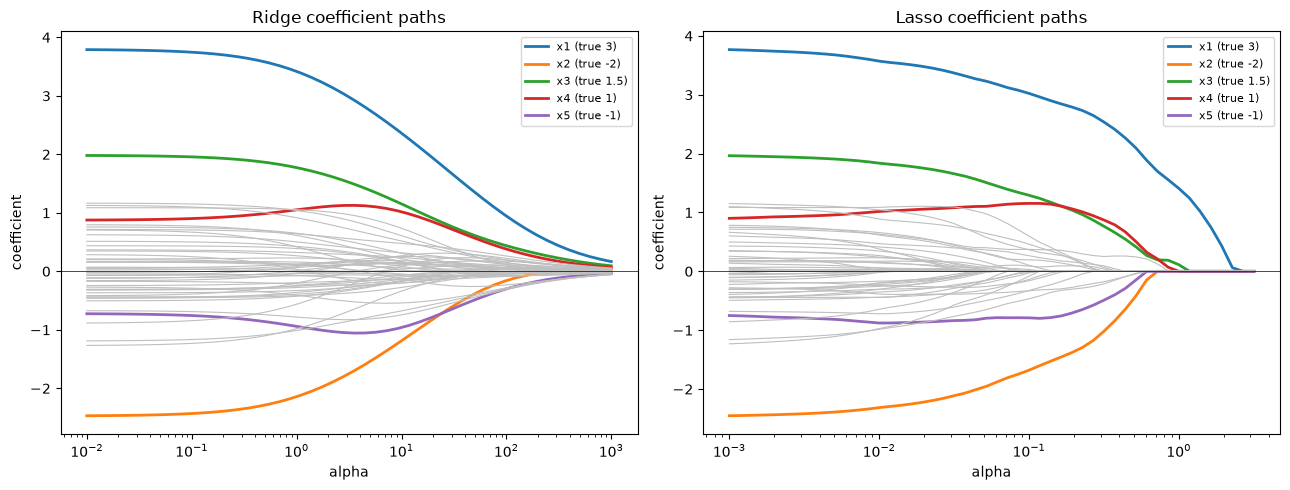

         chosen alpha  test MSE  non-zero coefficients
model                                                 
RidgeCV        5.6899    7.6061                     50
LassoCV        0.1389    4.9480                     18


In [13]:
ridge_coefs = np.vstack([Ridge(alpha=a).fit(X3_train, y3_train).coef_ for a in ridge_alphas])
lasso_coefs = np.vstack([Lasso(alpha=a, max_iter=100000).fit(X3_train, y3_train).coef_ for a in lasso_alphas])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_paths(ridge_alphas, ridge_coefs, "Ridge coefficient paths", axes[0])
plot_paths(lasso_alphas, lasso_coefs, "Lasso coefficient paths", axes[1])
plt.tight_layout()
plt.show()

cv_split = KFold(5, shuffle=True, random_state=0)
ridge_cv = RidgeCV(alphas=ridge_alphas, cv=cv_split).fit(X3_train, y3_train)
lasso_cv = LassoCV(alphas=lasso_alphas, cv=cv_split).fit(X3_train, y3_train)

rows_3b = []
for name, model in [("RidgeCV", ridge_cv), ("LassoCV", lasso_cv)]:
    pred = model.predict(X3_test)
    rows_3b.append({
        "model": name,
        "chosen alpha": model.alpha_,
        "test MSE": mse(y3_test, pred),
        "non-zero coefficients": int((np.abs(model.coef_) > 1e-8).sum()),
    })
results_3b = pd.DataFrame(rows_3b).set_index("model")
print(results_3b.to_string(float_format="{:.4f}".format))


Now real data. We try to predict AAPL's return tomorrow from the returns of all seven series over the last five days: 35 predictors. The first 70% of the sample is used for fitting and the last 30% for testing, and the predictors are standardized with the training part's mean and standard deviation.

In [14]:
lags = pd.concat({f'{c}_lag{k}': data[c].shift(k - 1) for c in data.columns for k in range(1, 6)}, axis=1)
s3 = lags.join(data['AAPL'].shift(-1).rename('next_AAPL')).dropna()   # lag1 is today's return
cut = int(0.7 * len(s3))

X3s = s3.drop(columns='next_AAPL').values
y3s = s3['next_AAPL'].values
scaler = StandardScaler().fit(X3s[:cut])
X3s_train, X3s_test = scaler.transform(X3s[:cut]), scaler.transform(X3s[cut:])
y3s_train, y3s_test = y3s[:cut], y3s[cut:]
print(X3s_train.shape, X3s_test.shape)

(1053, 35) (452, 35)


**Task 3C.** Fit `LinearRegression()`, `RidgeCV(alphas=np.logspace(-1, 5, 50), cv=TimeSeriesSplit(5))` and `LassoCV(alphas=np.logspace(-5, -1, 50), cv=TimeSeriesSplit(5))` on the training part. For each, report the in-sample $R^2$, the test-period $R^2_{\text{oos}}$ (with `oos_r2` from Section 2), the chosen $\alpha$ and the number of non-zero coefficients.

Reference: OLS has an in-sample $R^2$ of 0.0863 and $R^2_{\text{oos}}$ = -0.1073; LassoCV keeps 0 coefficients.

In [15]:
models_3c = {
    "OLS": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=np.logspace(-1, 5, 50), cv=TimeSeriesSplit(5)),
    "LassoCV": LassoCV(alphas=np.logspace(-5, -1, 50), cv=TimeSeriesSplit(5), max_iter=100000),
}
rows_3c = []
for name, model in models_3c.items():
    model.fit(X3s_train, y3s_train)
    train_pred = model.predict(X3s_train)
    test_pred = model.predict(X3s_test)
    row = {
        "model": name,
        "in-sample R²": 1 - ((y3s_train - train_pred) ** 2).sum() / ((y3s_train - y3s_train.mean()) ** 2).sum(),
        "test R²_oos": oos_r2(y3s_test, test_pred, y3s_train.mean()),
        "chosen alpha": getattr(model, "alpha_", np.nan),
        "non-zero coefficients": int((np.abs(model.coef_) > 1e-8).sum()),
    }
    rows_3c.append(row)
results_3c = pd.DataFrame(rows_3c).set_index("model")
print(results_3c.to_string(float_format="{:.4f}".format))


         in-sample R²  test R²_oos  chosen alpha  non-zero coefficients
model                                                                  
OLS            0.0863      -0.1073           NaN                     35
RidgeCV        0.0024      -0.0013   100000.0000                     35
LassoCV        0.0000       0.0000        0.0041                      0


**Question 3.1**

Using Tasks 3A and 3B, describe how Ridge and Lasso treat the coefficients differently as $\alpha$ grows. Which did better here, and why does that suit this particular data? Why must the predictors be standardized before either is applied?

**Answer:**

Ridge penalizes the squared coefficients while Lasso penalizes the absolute coefficients. Hence, as $\alpha$ grows Ridge while decrease the coefficient more smoothly while Lasso may not behave very smooth. Also, Lasso allows the coefficient to be zero when it contibutes to small to justify the penalty since they are of the same dimension, but Ridge only shrinks coefficients towards zero.

Neither of them did a good job in predicting the AAPL's return since they all basically set the coefficients to zero and cannot beat the training mean prediction.

Predictors must be standardize otherwise the coefficient while be affected by the scale and so does the penalty towards that coefficient.

**Question 3.2**

Interpret Task 3C. What does the gap between OLS's in-sample and out-of-sample $R^2$ mean, and what is Lasso telling you when it sets every coefficient to zero?

**Answer:**

The gap means overfitting? Historical pattern is not valid for the later period. 

The Lasso suggests that none of the predictors is good enough to keep by testing the out-of-sample $R^2$.

# 4. Regression When Assumptions Fail

Week 1 found that stock returns violate the classical assumptions: the error variance grows with the size of the market move, and there are far more extreme days than a normal distribution allows. Robust standard errors fixed the inference, but the estimator itself was still OLS. This section changes the estimator.

- **Weighted least squares (WLS)** gives less weight to observations with a larger error variance.
- **Huber regression** behaves like least squares for small errors and like absolute errors for large ones, so extreme days pull less.
- **Least absolute deviations (LAD)** minimizes $\sum |y_t - x_t^\top\beta|$; it estimates the conditional **median** instead of the mean.
- **Quantile regression** generalizes LAD to any quantile $q$: it estimates how the $q$-th quantile of $Y$ moves with $X$.

**Task 4A.** For TSLA on `MKT`:

1. Fit OLS and report $\hat\beta$ with its classical and HC1 standard errors.
2. Estimate the error variance of each day by regressing the squared OLS residuals on a constant and $|m_t|$, the absolute value of `MKT` on day $t$ (in decimal units, as in `data`); the fitted values are the variance estimates.
3. Fit WLS with weights equal to one over those variance estimates (`sm.WLS`), and report $\hat\beta$ with its classical and HC1 standard errors.

Reference: OLS $\hat\beta$ = 1.5605 (HC1 SE 0.1067); WLS $\hat\beta$ = 1.6998 (HC1 SE 0.0918).

In [16]:
y4 = data["TSLA"]
X4 = sm.add_constant(data["MKT"])
ols4 = sm.OLS(y4, X4).fit()
ols4_hc1 = ols4.get_robustcov_results(cov_type="HC1")

# Model the conditional error variance as a linear function of |MKT|.
abs_mkt = data["MKT"].abs()
variance_X = sm.add_constant(abs_mkt)
variance_model = sm.OLS(ols4.resid ** 2, variance_X).fit()
variance_estimates = variance_model.fittedvalues.clip(lower=1e-12)

wls4 = sm.WLS(y4, X4, weights=1 / variance_estimates).fit()
wls4_hc1 = wls4.get_robustcov_results(cov_type="HC1")

results_4a = pd.DataFrame({
    "OLS": ols4.params,
    "OLS classical SE": ols4.bse,
    "OLS HC1 SE": ols4_hc1.bse,
    "WLS": wls4.params,
    "WLS classical SE": wls4.bse,
    "WLS HC1 SE": wls4_hc1.bse,
})
print(results_4a.to_string(float_format="{:.4f}".format))


         OLS  OLS classical SE  OLS HC1 SE    WLS  WLS classical SE  WLS HC1 SE
const 0.0017            0.0009      0.0009 0.0021            0.0009      0.0009
MKT   1.5605            0.0721      0.1067 1.6998            0.0924      0.0918


**Task 4B.** For each of the six stocks, estimate the slope on `MKT` by OLS, by Huber regression (`sm.RLM` with `sm.robust.norms.HuberT()`) and by LAD (`sm.QuantReg` with `q=0.5`), and report the three slopes in one table.

Reference: for AMZN, the slope is 1.0972 by OLS, 1.1957 by Huber and 1.2126 by LAD.

In [17]:
stocks = ["AAPL", "AMZN", "GOOGL", "MSFT", "NVDA", "TSLA"]
rows_4b = []
for stock in stocks:
    y = data[stock]
    X = sm.add_constant(data["MKT"])
    ols_model = sm.OLS(y, X).fit()
    huber_model = sm.RLM(y, X, M=sm.robust.norms.HuberT()).fit()
    lad_model = sm.QuantReg(y, X).fit(q=0.5)
    rows_4b.append({
        "stock": stock,
        "OLS slope": ols_model.params["MKT"],
        "Huber slope": huber_model.params["MKT"],
        "LAD slope": lad_model.params["MKT"],
    })
results_4b = pd.DataFrame(rows_4b).set_index("stock")
print(results_4b.to_string(float_format="{:.4f}".format))


       OLS slope  Huber slope  LAD slope
stock                                   
AAPL      1.1986       1.1860     1.2078
AMZN      1.0972       1.1957     1.2126
GOOGL     1.1423       1.1336     1.1635
MSFT      1.1821       1.1828     1.1607
NVDA      1.7907       1.8092     1.8247
TSLA      1.5605       1.6116     1.5566


**Task 4C.** For TSLA on `MKT`, run quantile regressions for $q$ = 0.05, 0.25, 0.5, 0.75 and 0.95. Report the slope and its standard error for each $q$, and plot the five fitted lines over the scatter of TSLA against `MKT`.

Reference: the slope is 1.2901 (SE 0.3055) at q = 0.05 and 1.7143 (SE 0.2097) at q = 0.95.

          slope  slope SE
quantile                 
0.05     1.2901    0.3055
0.25     1.6151    0.0790
0.50     1.5566    0.0662
0.75     1.6177    0.0871
0.95     1.7143    0.2097


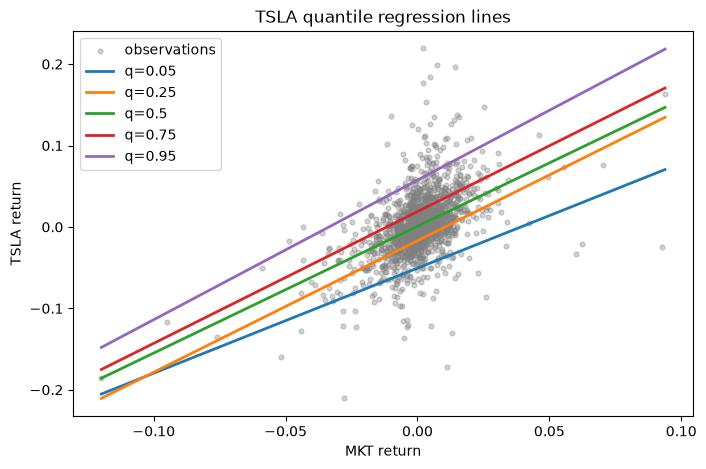

In [18]:
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
y = data["TSLA"]
X = sm.add_constant(data["MKT"])
rows_4c = []
quantile_models = {}
for q in quantiles:
    model = sm.QuantReg(y, X).fit(q=q)
    quantile_models[q] = model
    rows_4c.append({"quantile": q, "slope": model.params["MKT"], "slope SE": model.bse["MKT"]})
results_4c = pd.DataFrame(rows_4c).set_index("quantile")
print(results_4c.to_string(float_format="{:.4f}".format))

m_grid4 = np.linspace(data["MKT"].min(), data["MKT"].max(), 300)
X_grid4 = sm.add_constant(m_grid4)
plt.figure(figsize=(8, 5))
plt.scatter(data["MKT"], y, s=12, alpha=0.35, color="gray", label="observations")
for q, model in quantile_models.items():
    plt.plot(m_grid4, model.predict(X_grid4), lw=2, label=f"q={q:g}")
plt.xlabel("MKT return")
plt.ylabel("TSLA return")
plt.title("TSLA quantile regression lines")
plt.legend()
plt.show()


**Question 4.1**

WLS, Huber/LAD and quantile regression each address a different problem. For each, state what it changes compared with OLS and when you would use it, using your results: why did WLS move TSLA's slope and its HC1 standard error, why do OLS and the robust slopes disagree most for AMZN, and do TSLA's quantile slopes differ by more than their standard errors allow? What would it mean for a single $\beta$ if they did?

**Answer:**

WLS addresses the problem that error variance is different for different market return. Huber/LAD addresses the problem that OLS amplies the larger error term in extreme condition. Quantile addresses the problem that the spread of return changes as X changes(since we use different quantile of Y to do regression).

I will use WLS if I have clear idea about how error variance is going to change, for example, by the linear regression with absolute market returns. I will use Huber/LAD if I don't have such clear idea but I want to minimize the effect of extreme days. I will use quantile only to test how the spread is going change.

WSL increase the slope because TESLA error variance is large when MKT is extreme and WSL minimize the effect of such condition. It decrease the HC1 error because the slope is find without assuming error variance being constant and hence have better predictibility.

For AMZN, OSL slope and robust slope may disagree most because AMZN contains more extreme days. For TESLA Quantile, the slope of 5th and 95th differs by 0.42 while the standard error is around 0.21 and 0.31. So yes they differ more and this is mainly because the upper and lower tails of TESLA responds quite differently to the market. This suggests that single beta is not enough to capture the relationship. We can use piecewise linear regression to address that.

# 5. Regression for Probabilities

When the outcome is binary, such as whether a stock rises on a given day, the quantity to estimate is a probability: $\mathbb{E}[Y \mid X] = P(Y = 1 \mid X)$.

- The **linear probability model** (LPM) simply runs OLS on the 0/1 outcome.
- **Logistic regression** models the log-odds as linear: $\log \frac{p}{1 - p} = a + b\,x$, so that $p = \frac{1}{1 + e^{-(a + b x)}}$ always lies between 0 and 1.

Probability forecasts are judged by how close they are to what happens:

- **Log loss**: $-\frac{1}{n}\sum \left[y \log \hat p + (1 - y)\log(1 - \hat p)\right]$; lower is better, and confident wrong forecasts are punished heavily.
- **Brier score**: $\frac{1}{n}\sum (\hat p - y)^2$; lower is better.
- **Calibration**: among the days given a probability of about 70%, about 70% should turn out to be up days.

Below, `up` is 1 on days when AAPL rose and `m` is the market return in percent.

In [19]:
up = (data['AAPL'] > 0).astype(int)
m = data['MKT'] * 100
cut5 = int(0.7 * len(up))
m_grid = np.linspace(m.min(), m.max(), 300)


def calibration_table(p, y, n_bins=10):
    """Group forecasts into n_bins equal-count bins; compare the mean forecast with the observed frequency."""
    p, y = np.asarray(p), np.asarray(y)
    bins = pd.qcut(p, n_bins, duplicates='drop')
    return (pd.DataFrame({'mean_forecast': p, 'observed_frequency': y})
              .groupby(bins, observed=True).mean())


def plot_calibration(tables, ax):
    """tables: dict mapping a label to a calibration_table."""
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect calibration')
    for label, t in tables.items():
        ax.plot(t['mean_forecast'], t['observed_frequency'], 'o-', label=label)
    ax.set_xlabel('mean forecast probability')
    ax.set_ylabel('observed frequency of up days')
    ax.legend()

**Task 5A.** Using the full sample, regress `up` on `m` with an LPM (`sm.OLS`) and with logistic regression (`sm.Logit`). Report both sets of coefficients and the number of days on which the LPM's fitted probability lies outside $[0, 1]$. Plot both fitted curves over `m_grid`.

Reference: the logistic slope is 1.8619; the LPM gives 70 fitted probabilities outside [0, 1].

Optimization terminated successfully.
         Current function value: 0.489646
         Iterations 7
LPM coefficients:
const   0.5290
MKT     0.1969

Logistic coefficients:
const   0.0768
MKT     1.8619

LPM fitted probabilities outside [0, 1]: 70


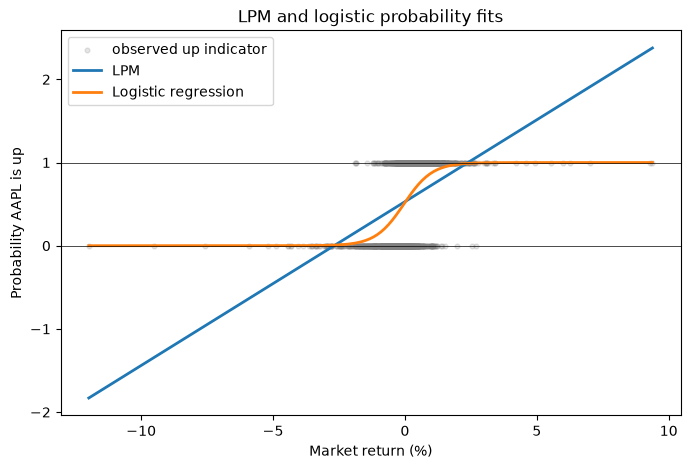

In [20]:
X5 = sm.add_constant(m)
lpm5 = sm.OLS(up, X5).fit()
logit5 = sm.Logit(up, X5).fit()

lpm_fitted = lpm5.predict(X5)
outside = int(((lpm_fitted < 0) | (lpm_fitted > 1)).sum())
print("LPM coefficients:")
print(lpm5.params.to_string(float_format="{:.4f}".format))
print("\nLogistic coefficients:")
print(logit5.params.to_string(float_format="{:.4f}".format))
print(f"\nLPM fitted probabilities outside [0, 1]: {outside}")

X5_grid = sm.add_constant(m_grid)
plt.figure(figsize=(8, 5))
plt.scatter(m, up, s=12, alpha=0.2, color="gray", label="observed up indicator")
plt.plot(m_grid, lpm5.predict(X5_grid), lw=2, label="LPM")
plt.plot(m_grid, logit5.predict(X5_grid), lw=2, label="Logistic regression")
plt.axhline(0, color="black", lw=0.5)
plt.axhline(1, color="black", lw=0.5)
plt.xlabel("Market return (%)")
plt.ylabel("Probability AAPL is up")
plt.title("LPM and logistic probability fits")
plt.legend()
plt.show()


**Task 5B.** From the logistic fit in Task 5A, compute the odds ratio for a 1-percentage-point rise in the market ($e^{b}$), and the fitted probability of an up day when the market moves -1%, 0% and +1%.

Reference: the odds ratio is 6.436; the probabilities are 0.1437, 0.5192 and 0.8742.

In [21]:
logit_slope = logit5.params["MKT"]
odds_ratio_1pp = np.exp(logit_slope)
market_scenarios = pd.DataFrame({"const": 1.0, "MKT": [-1.0, 0.0, 1.0]})
scenario_probs = logit5.predict(market_scenarios)
print(f"Odds ratio for a 1 percentage-point increase in MKT: {odds_ratio_1pp:.4f}")
print("Fitted probability of an AAPL up day:")
print(pd.Series(scenario_probs.to_numpy(), index=["MKT = -1%", "MKT = 0%", "MKT = +1%"]).to_string(float_format="{:.4f}".format))


Odds ratio for a 1 percentage-point increase in MKT: 6.4362
Fitted probability of an AAPL up day:
MKT = -1%   0.1437
MKT = 0%    0.5192
MKT = +1%   0.8742


**Task 5C.** Fit the logistic regression on the first `cut5` days only and forecast the rest. On the test days, report the log loss, the Brier score and the accuracy (forecast above 0.5 counts as "up") of the logistic forecasts, and of a constant forecast equal to the training-period frequency of up days. Show the calibration table of the logistic forecasts.

Reference: the logistic log loss is 0.5751 against 0.6877 for the constant forecast; the Brier scores are 0.1933 and 0.2473.

In [22]:
up_train, up_test = up.iloc[:cut5], up.iloc[cut5:]
m_train, m_test = m.iloc[:cut5], m.iloc[cut5:]
X_train5 = sm.add_constant(m_train)
X_test5 = sm.add_constant(m_test)
logit5_train = sm.Logit(up_train, X_train5).fit(disp=False)
p_logit5 = logit5_train.predict(X_test5)
base_rate5 = up_train.mean()
p_const5 = np.full(len(up_test), base_rate5)

metrics_5c = pd.DataFrame({
    "log loss": [log_loss(up_test, p_logit5), log_loss(up_test, p_const5)],
    "Brier score": [brier_score_loss(up_test, p_logit5), brier_score_loss(up_test, p_const5)],
    "accuracy": [((p_logit5 > 0.5) == up_test.to_numpy()).mean(), ((p_const5 > 0.5) == up_test.to_numpy()).mean()],
}, index=["Logistic", "Training-frequency constant"])
print(metrics_5c.to_string(float_format="{:.4f}".format))

calibration_5c = calibration_table(p_logit5, up_test.to_numpy())
print("\nLogistic forecast calibration table:")
print(calibration_5c.to_string(float_format="{:.4f}".format))


                             log loss  Brier score  accuracy
Logistic                       0.5751       0.1933    0.7263
Training-frequency constant    0.6877       0.2473    0.5563

Logistic forecast calibration table:
                  mean_forecast  observed_frequency
(0.00166, 0.174]         0.0806              0.0435
(0.174, 0.289]           0.2279              0.3333
(0.289, 0.411]           0.3538              0.3778
(0.411, 0.494]           0.4434              0.4000
(0.494, 0.559]           0.5258              0.6522
(0.559, 0.635]           0.5932              0.6667
(0.635, 0.722]           0.6821              0.7556
(0.722, 0.819]           0.7718              0.7111
(0.819, 0.898]           0.8594              0.6889
(0.898, 0.994]           0.9371              0.9348


**Task 5D.** Repeat Task 5C with a genuine forecast: predict whether AAPL rises **tomorrow** from the market return **today** (use `m.shift(1)` as the predictor and drop the first day). Split the remaining days 70/30 as in Task 5C, recomputing the split point on this shorter sample. Report the same three metrics against the constant forecast, the range of the forecast probabilities, and plot the calibration of both models (Task 5C and this one) with `plot_calibration`.

Reference: the logistic log loss is 0.6917 against 0.6877 for the constant forecast; the forecasts range from 0.463 to 0.622.

                             log loss  Brier score  accuracy
Logistic                       0.6917       0.2493    0.5541
Training-frequency constant    0.6877       0.2473    0.5563

Logistic forecast probability range: 0.463 to 0.622


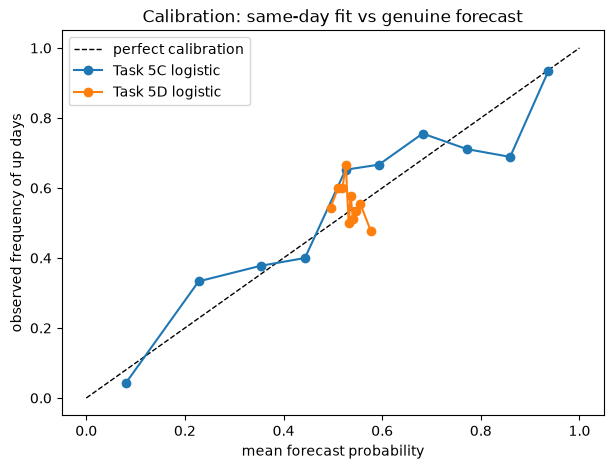

In [23]:
m_lagged = m.shift(1).dropna()
up_lagged = up.loc[m_lagged.index]
cut5d = int(0.7 * len(up_lagged))
m_train5d, m_test5d = m_lagged.iloc[:cut5d], m_lagged.iloc[cut5d:]
up_train5d, up_test5d = up_lagged.iloc[:cut5d], up_lagged.iloc[cut5d:]
X_train5d = sm.add_constant(m_train5d)
X_test5d = sm.add_constant(m_test5d)
logit5d = sm.Logit(up_train5d, X_train5d).fit(disp=False)
p_logit5d = logit5d.predict(X_test5d)
base_rate5d = up_train5d.mean()
p_const5d = np.full(len(up_test5d), base_rate5d)

metrics_5d = pd.DataFrame({
    "log loss": [log_loss(up_test5d, p_logit5d), log_loss(up_test5d, p_const5d)],
    "Brier score": [brier_score_loss(up_test5d, p_logit5d), brier_score_loss(up_test5d, p_const5d)],
    "accuracy": [((p_logit5d > 0.5) == up_test5d.to_numpy()).mean(), ((p_const5d > 0.5) == up_test5d.to_numpy()).mean()],
}, index=["Logistic", "Training-frequency constant"])
print(metrics_5d.to_string(float_format="{:.4f}".format))
print(f"\nLogistic forecast probability range: {p_logit5d.min():.3f} to {p_logit5d.max():.3f}")

calibration_5d = calibration_table(p_logit5d, up_test5d.to_numpy())
fig, ax = plt.subplots(figsize=(7, 5))
plot_calibration({"Task 5C logistic": calibration_5c, "Task 5D logistic": calibration_5d}, ax)
ax.set_title("Calibration: same-day fit vs genuine forecast")
plt.show()


**Question 5.1**

Using Tasks 5A and 5B, why is logistic regression preferred to the LPM for probabilities? Interpret the logistic slope in plain words.

**Answer:**
- It gives propability ranging from 0 to 1 with smooth change in extreme case. 
- It has sensible shape since changing from 98% to 99% requires more evidence than changing from 60% to 61%.

1% increase in predictor will amplify the odd by $e^{\text{slope}}%$.

**Question 5.2**

Compare Tasks 5C and 5D using log loss, the Brier score, accuracy and the calibration plot. What does each metric tell you that the others do not, and why is the model in Task 5C not a forecasting model even though it scores well?

**Answer:**

5C gives much better performance metrics for in-sample and slightly better performance metrics for out-of-sample. The log loss penalize more for being confidently wrong; the Brier score also takes confidence into account but only penalize it in "squared" sense; The accuracy only consider when model forecast "up", what's the probability that the result is "up"; Calibration plot tells whether the actual "up" days is more or less than the predicted "up" days(ie the probability of "up"). Also, it is interesting to notice that Task 5D only gives forecast clustered near 50%, suggesting weak signal.

Task 5C is not a forecasting model since we cannot get the market return until the end of day which we will also know the AAPL return at that time.